# D4 – L'énergie par région

**Python numérique – devoir n° 4 – à rendre pour le dimanche 11 octobre 2026, 23 h 59** (la séance 5 est le mardi 13)

Bienvenue dans votre quatrième devoir ! Nous allons y mettre en pratique les notions vues en séance 4 : `sort_values`, `groupby`, `pivot_table`, `merge` / `concat`, `pd.cut`, ainsi qu'un premier graphique tracé directement depuis `pandas`. Pour ce faire, nous allons travailler sur la production d'électricité des régions françaises.

Durée indicative : 1 h 30.

````{admonition} Consignes de rendu
:class: important

* Ce notebook reste dans le dossier `D4/` de votre dépôt `pe-homework` (celui que le zip du sujet a créé en se dézippant), avec ses figures à côté, puis il doit être **commité et poussé** (`git add`, `git commit`, `git push`) avant la deadline. Attention, c'est la **date du commit** qui fait foi, pas celle du push ; le nom du fichier, lui, n'a pas d'importance (`sujet.ipynb` convient très bien). Le dossier `data/` livré avec le sujet reste lui aussi dans `D4/` : `git add D4` embarque tout le dossier, et c'est très bien ainsi (il ne pèse que quelques kilo-octets).
* Juste avant de rendre, **pensez à ré-exécuter toutes les cellules** via *Kernel → Restart Kernel and Run All Cells* : toutes doivent s'exécuter dans l'ordre et sans erreur. En effet, un notebook qui plante à mi-chemin sera corrigé jusqu'à l'erreur…
* Le notebook lit les données dans le sous-dossier `data/` (chemins relatifs `data/energie-regions.csv` et `data/population-regions.csv`) ; la figure `energie.png` et le fichier `energie-par-habitant.csv` sont quant à eux écrits dans le dossier du notebook.
* Les cellules `# votre code` sont à compléter ; vous pouvez ajouter autant de cellules que vous le souhaitez. Les cellules de test (`assert`) sont là pour vous aider : si elles passent sans erreur, c'est bon signe. Ne les modifiez pas !
* Répondez aux questions "en français" dans une cellule *Markdown*, en deux ou trois phrases.
````

````{admonition} Ce qui est autorisé
:class: note

* La documentation de `pandas` / `matplotlib`, les notebooks du cours, vos notes.
* Les assistants IA sont tolérés, avec la règle habituelle : **vous devez être capable d'expliquer chaque ligne que vous rendez**, et je pourrai vous demander de le faire à l'oral en séance. Le devoir est individuel.
* En revanche, pas de boucle `for` sur les lignes d'une table : tout se fait avec les opérations `pandas`. Je tolère toutefois une boucle sur les 6 *colonnes* du tableau croisé, là où c'est indiqué.
````

````{admonition} Les données
:class: warning

`data/energie-regions.csv` donne, pour chacune des 13 régions de France métropolitaine et pour six filières (nucléaire, hydraulique, éolien, solaire, thermique, bioénergies), une production annuelle d'électricité en GWh. `data/population-regions.csv` donne la population de chaque région.

Attention, ce sont des **données simplifiées** : j'ai arrondi des ordres de grandeur inspirés des bilans électriques régionaux publiés par RTE, afin de construire un jeu de données commode pour l'exercice. Elles ne sont donc pas citables et ne doivent pas être utilisées en dehors de ce devoir. Notez enfin que certaines combinaisons région × filière sont absentes du fichier (pas de centrale nucléaire en Bretagne, par ex.) : c'est voulu !
````

## Barème

| Exercice | Contenu | Points |
|---|---|---|
| 1 | Chargement et exploration | 2 |
| 2 | Production totale par région (`groupby`, tri) | 3 |
| 3 | Tableau croisé région × filière (`pivot_table`), parts, classements | 4 |
| 4 | Figure en barres empilées `energie.png` | 3 |
| 5 | Population, kWh par habitant (`merge`, `pd.cut`), export CSV | 6 |
| – | Notebook propre : exécuté sans erreur, réponses rédigées, figure légendée | 2 |
| **Total** | | **20** |
| Bonus | Part renouvelable, ligne « France » (`concat`) | +2 |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Exercice 1 – Chargement et exploration (2 pts)

**1.a** Lisez `data/energie-regions.csv` dans une `DataFrame` `df`, puis affichez ses premières lignes et le résultat de `df.info()`. Attention, le séparateur n'est pas celui par défaut : au besoin, ouvrez le fichier pour le vérifier.

In [2]:
df=pd.read_csv("data/energie-regions.csv",sep=";") #il faut séparer avec des ;
df.head()

,region,filiere,production_gwh
0,Auvergne-Rhône-Alpes,nucléaire,110000
1,Auvergne-Rhône-Alpes,hydraulique,25000
2,Auvergne-Rhône-Alpes,éolien,1200
3,Auvergne-Rhône-Alpes,solaire,2000
4,Auvergne-Rhône-Alpes,thermique,2500


In [3]:
#résultat de df.info() sinon, df.head() n'était pas affiché, seul le dernier l'est
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   region          70 non-null     str  
 1   filiere         70 non-null     str  
 2   production_gwh  70 non-null     int64
dtypes: int64(1), str(2)
memory usage: 3.4 KB


In [4]:
assert df.shape == (70, 3)
assert list(df.columns) == ["region", "filiere", "production_gwh"]
assert df["production_gwh"].dtype.kind in "iu"
print("ok")

ok


**1.b** Combien la table compte-t-elle de régions distinctes ? de filières distinctes ? Si toutes les combinaisons région × filière étaient présentes, combien de lignes aurait-elle ? Combien en manque-t-il ?

In [5]:
# votre code
n_regions=len(df["region"].unique())
n_filieres=len(df["filiere"].unique())
print(str(n_regions)+" régions distinctes")
print(str(n_filieres)+" filières distinctes")

13 régions distinctes
6 filières distinctes


La table compte 13 régions et six filières distinctes.

In [6]:
assert n_regions == 13 and n_filieres == 6
print("ok")

ok


## Exercice 2 – Production totale par région (3 pts)

**2.a** Calculez la `Series` `total` donnant la production totale (toutes filières confondues) de chaque région, indexée par le nom de la région et triée par ordre décroissant.

In [7]:
total=df.groupby("region")["production_gwh"].sum()
total=total.sort_values(ascending=False)
total

region
Auvergne-Rhône-Alpes          142200
Grand Est                      84000
Centre-Val de Loire            74950
Nouvelle-Aquitaine             62400
Normandie                      54900
Hauts-de-France                50310
Occitanie                      38800
Provence-Alpes-Côte d'Azur     16900
Pays de la Loire                8100
Bretagne                        5700
Île-de-France                   5450
Bourgogne-Franche-Comté         3900
Corse                           2190
Name: production_gwh, dtype: int64

In [8]:
assert isinstance(total, pd.Series)
assert len(total) == 13
assert total.index[0] == "Auvergne-Rhône-Alpes" and total.iloc[0] == 142200
assert total.index[-1] == "Corse"
assert total.is_monotonic_decreasing
assert total.sum() == 549800
print("ok")

ok


**2.b** Quelle est la production totale de la France métropolitaine (en GWh, puis en TWh) ? Quelle part (en %) représente la première région ? Les trois premières régions réunies ?

In [9]:
prod_tot = total.drop(index="Corse").sum() #pas la Corse dans la France métropolitaine
tot=total.sum()
pourcentages=total/tot #on divise par le total

print("production totale de la France métropolitaine : "+str(prod_tot))
print("part de la première région : "+str(pourcentages.iloc[0]))
print("part des trois premières régions réunies : "+str(pourcentages.iloc[0:3].sum()))


production totale de la France métropolitaine : 547610
part de la première région : 0.2586395052746453
part des trois premières régions réunies : 0.5477446344125136


## Exercice 3 – Tableau croisé région × filière (4 pts)

**3.a** Construisez avec `pivot_table` la table `croise` : une ligne par région, une colonne par filière, et la production en GWh dans les cases. Les combinaisons absentes doivent valoir 0 et non `NaN` ; l'argument `fill_value` est là pour cela. Précisez également `aggfunc="sum"` : certes, il n'y a qu'une valeur par case, mais l'agrégation par défaut (la moyenne) transformerait tout en flottants. Vérifiez enfin que la somme de chaque ligne redonne bien `total` — attention, `total` n'est pas trié dans le même ordre.

In [63]:
croise=df.pivot_table(index="region",columns="filiere",values="production_gwh",aggfunc="sum")
croise = croise.fillna(0)
croise

filiere,bioénergies,hydraulique,nucléaire,solaire,thermique,éolien
region,,,,,,
Auvergne-Rhône-Alpes,1500.0,25000.0,110000.0,2000.0,2500.0,1200.0
Bourgogne-Franche-Comté,600.0,600.0,0.0,700.0,300.0,1700.0
Bretagne,700.0,500.0,0.0,500.0,1200.0,2800.0
Centre-Val de Loire,400.0,150.0,70000.0,900.0,300.0,3200.0
Corse,50.0,600.0,0.0,300.0,1200.0,40.0
Grand Est,1500.0,8000.0,60000.0,1500.0,3500.0,9500.0
Hauts-de-France,1300.0,10.0,32000.0,500.0,4000.0,12500.0
Normandie,500.0,100.0,50000.0,300.0,2000.0,2000.0
Nouvelle-Aquitaine,1500.0,7000.0,45000.0,5000.0,900.0,3000.0


In [11]:
assert croise.shape == (13, 6)
assert set(croise.columns) == {"nucléaire", "hydraulique", "éolien", "solaire", "thermique", "bioénergies"}
assert croise.isna().sum().sum() == 0
assert croise.loc["Bretagne", "nucléaire"] == 0
assert croise.loc["Auvergne-Rhône-Alpes", "hydraulique"] == 25000
assert (croise.sum(axis=1) == total.loc[croise.index]).all()
print("ok")

ok


**3.b** Ajoutez à une **copie** de `croise` (ou dans une `Series` séparée `part_nucleaire`) la part du nucléaire dans la production de chaque région, en %. Affichez-la triée par ordre décroissant. Combien de régions n'ont aucune production nucléaire ?

In [12]:
part_nucleaire=croise["nucléaire"]/croise.sum(axis=1)*100
part_nucleaire=part_nucleaire.sort_values(ascending=False)
part_nucleaire

region
Centre-Val de Loire           93.395597
Normandie                     91.074681
Auvergne-Rhône-Alpes          77.355837
Nouvelle-Aquitaine            72.115385
Grand Est                     71.428571
Hauts-de-France               63.605645
Occitanie                     43.814433
Bourgogne-Franche-Comté        0.000000
Bretagne                       0.000000
Corse                          0.000000
Pays de la Loire               0.000000
Provence-Alpes-Côte d'Azur     0.000000
Île-de-France                  0.000000
dtype: float64

In [13]:
assert part_nucleaire.shape == (13,)
assert abs(part_nucleaire["Centre-Val de Loire"] - 93.4) < 0.1
assert (part_nucleaire == 0).sum() == 6
print("ok")

ok


````{admonition} Pas encore vu en cours : idxmax et nlargest
:class: note

`serie.idxmax()` renvoie l'*étiquette* de la plus grande valeur, là où `serie.max()` renvoie la valeur elle-même ; appliqué à une `DataFrame`, `df.idxmax()` le fait colonne par colonne et renvoie une `Series`. De son côté, `serie.nlargest(3)` renvoie les trois plus grandes valeurs déjà triées, avec leur index. Notez enfin qu'il existe les versions "minimum", `idxmin` et `nsmallest`.
````

**3.c** Pour chaque filière, quelle région produit le plus ? Construisez en une ligne la `Series` `championnes`, indexée par la filière et contenant le nom de la région. Affichez ensuite, pour chaque filière, les trois premières régions avec leur production — c'est ici, exceptionnellement, qu'une boucle `for` sur les colonnes est tolérée.

In [14]:
championnes=croise.idxmax()

for col in croise:
    print(str(col)+" : ")
    print(croise[str(col)].nlargest(3))
    print("\n") #saut de ligne pour plus de visibilité

bioénergies : 
region
Île-de-France           2500.0
Auvergne-Rhône-Alpes    1500.0
Grand Est               1500.0
Name: bioénergies, dtype: float64


hydraulique : 
region
Auvergne-Rhône-Alpes          25000.0
Occitanie                     12000.0
Provence-Alpes-Côte d'Azur    10000.0
Name: hydraulique, dtype: float64


nucléaire : 
region
Auvergne-Rhône-Alpes    110000.0
Centre-Val de Loire      70000.0
Grand Est                60000.0
Name: nucléaire, dtype: float64


solaire : 
region
Nouvelle-Aquitaine            5000.0
Occitanie                     4500.0
Provence-Alpes-Côte d'Azur    2500.0
Name: solaire, dtype: float64


thermique : 
region
Hauts-de-France     4000.0
Grand Est           3500.0
Pays de la Loire    3500.0
Name: thermique, dtype: float64


éolien : 
region
Hauts-de-France    12500.0
Grand Est           9500.0
Occitanie           4000.0
Name: éolien, dtype: float64




In [15]:
assert championnes["nucléaire"] == "Auvergne-Rhône-Alpes"
assert championnes["éolien"] == "Hauts-de-France"
assert championnes["solaire"] == "Nouvelle-Aquitaine"
print("ok")

ok


## Exercice 4 – Figure (3 pts)

````{admonition} Pas encore vu en cours : dessiner depuis une DataFrame
:class: note

`df.plot.bar(...)` — comme `df.plot()` ou `df.plot.scatter(...)` — trace directement le contenu d'une table : une barre par ligne de l'index, une couleur par colonne, et `stacked=True` empile les colonnes au lieu de les juxtaposer. La méthode renvoie un objet `Axes` que l'on habille ensuite : `ax.set_title("…")`, `ax.set_ylabel("…")`, `ax.legend(title="…")`. On enregistre enfin la figure avec `plt.savefig("fig.png", dpi=120)`, **avant** `plt.show()`. Tout ceci sera repris en séance 5.
````

Tracez un diagramme en barres empilées de la production par région et par filière : une barre par région (triées par production totale décroissante), découpée par filière. Soignez la figure : donnez-lui un titre, nommez l'axe des ordonnées (GWh), rendez la légende lisible, et terminez par `plt.tight_layout()` afin que les noms de région ne soient pas coupés. Enregistrez le tout dans `energie.png`.

Puis, en deux phrases dans une cellule Markdown : qu'est-ce qui saute aux yeux ?

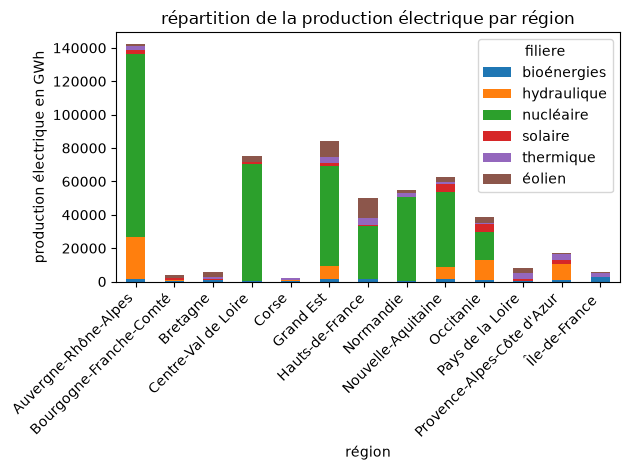

In [16]:
ax=croise.plot.bar(stacked=True)
ax.set_title("répartition de la production électrique par région")
ax.set_xlabel("région")
ax.set_ylabel("production électrique en GWh")
plt.xticks(rotation=45, ha="right") #penche les légendes des abcisses pour plus de lisibilité
plt.tight_layout()
plt.savefig("energie.png")
plt.show()


In [17]:
assert os.path.exists("energie.png")
print("ok")

ok


## Exercice 5 – Production par habitant (6 pts)

**5.a** Lisez `data/population-regions.csv` dans `pop`, puis fusionnez-le avec `total` afin d'obtenir une `DataFrame` `par_hab` à 13 lignes, aux colonnes `region`, `production_gwh` et `population`. Un indice : `merge` travaille sur deux `DataFrame`, or `total` est une `Series` indexée par la région — il faudra donc commencer par la remettre en forme (la clé de fusion est `region`).

In [23]:
pop=pd.read_csv("data/population-regions.csv",sep=";")
total=total.to_frame() #génère une erreur si réexécuté (to_frame() pas sur une DataFrame)
par_hab=pop.merge(total,on="region")

In [24]:
assert par_hab.shape == (13, 3)
assert set(par_hab.columns) == {"region", "production_gwh", "population"}
assert par_hab["population"].sum() == 65_780_000
print("ok")

ok


**5.b** Ajoutez la colonne `kwh_par_habitant`, c'est-à-dire la production annuelle par habitant, exprimée en kWh (1 GWh = 10⁶ kWh), puis triez `par_hab` par ordre décroissant de cette colonne. Quelle région produit le plus d'électricité par habitant ? le moins ? Quel est le rapport entre les deux ?

In [40]:
par_hab["kwh_par_habitant"]=par_hab["production_gwh"]/par_hab["population"]*10**6
ordre=par_hab["kwh_par_habitant"].sort_values(ascending=False).index #récupération des indices
par_hab=par_hab.loc[ordre] #réorganisation de par_hab
print("région produisant le plus d'électricité par habitant : "+str(par_hab.loc[par_hab["kwh_par_habitant"].idxmax(),"region"]))
print("région produisant le moins d'électricité par habitant : "+str(par_hab.loc[par_hab["kwh_par_habitant"].idxmin(),"region"]))
print("rapport entre les deux : "+str(float(par_hab.loc[par_hab["kwh_par_habitant"].idxmax(),"kwh_par_habitant"])/float(par_hab.loc[par_hab["kwh_par_habitant"].idxmin(),"kwh_par_habitant"])))

région produisant le plus d'électricité par habitant : Centre-Val de Loire
région produisant le moins d'électricité par habitant : Île-de-France
rapport entre les deux : 65.81837004248028


In [41]:
assert par_hab["kwh_par_habitant"].is_monotonic_decreasing
assert par_hab.iloc[0]["region"] == "Centre-Val de Loire"
assert abs(par_hab.iloc[0]["kwh_par_habitant"] - 29163) < 1
assert par_hab.iloc[-1]["region"] == "Île-de-France"
assert abs(par_hab.iloc[-1]["kwh_par_habitant"] - 443) < 1
print("ok")

ok


**5.c** Avec `pd.cut`, ajoutez une colonne `classe` qui range chaque région dans l'une des trois catégories `"faible"` (moins de 3 000 kWh/hab), `"moyenne"` (de 3 000 à 10 000) ou `"forte"` (plus de 10 000). Comptez les régions de chaque classe, puis affichez la production moyenne par habitant de chaque classe (sur une colonne catégorielle, `groupby` demande `observed=True`).

In [50]:
par_hab["classe"]=pd.cut(par_hab["kwh_par_habitant"],bins=[0,3000,10000,1000000000],labels=["faible","moyenne","forte"])
nombre=par_hab["classe"].value_counts()
print("nombre de régions dans chaque classe : ")
print(nombre)
print("\n")
moyennes=par_hab.groupby("classe",observed=True)["kwh_par_habitant"].mean()
print("nombre moyen de kwh par habitant par classe : ")
print(moyennes)

nombre de régions dans chaque classe : 
classe
forte      5
faible     4
moyenne    4
Name: count, dtype: int64


nombre moyen de kwh par habitant par classe : 
classe
faible      1397.335060
moyenne     6063.199649
forte      17695.734608
Name: kwh_par_habitant, dtype: float64


In [51]:
assert par_hab["classe"].dtype.name == "category"
assert par_hab["classe"].value_counts().to_dict() == {"forte": 5, "faible": 4, "moyenne": 4}
assert par_hab.set_index("region").loc["Corse", "classe"] == "moyenne"
print("ok")

ok


**5.d** Exportez `par_hab` (colonnes `region`, `kwh_par_habitant` arrondi à l'entier, `classe`) dans `energie-par-habitant.csv`, avec `;` comme séparateur et **sans** la colonne d'index. Relisez le fichier pour vérifier qu'il a bien 13 lignes et 3 colonnes.

In [59]:
par_hab["kwh_par_habitant"]=par_hab["kwh_par_habitant"].astype(int)
par_hab[["region","kwh_par_habitant","classe"]].to_csv("energie-par-habitant.csv",sep=";",index=False)

In [61]:
verif = pd.read_csv("energie-par-habitant.csv", sep=";")
assert verif.shape == (13, 3)
assert list(verif.columns) == ["region", "kwh_par_habitant", "classe"]
assert verif["kwh_par_habitant"].dtype.kind in "iu"
print("ok")

ok


## Bonus (+2)

**Bo.1** La part renouvelable d'une région est la part (en %) de hydraulique + éolien + solaire + bioénergies dans sa production totale. Calculez la `Series` `part_renouvelable` et affichez-la triée. Quelle région est la plus "verte" en proportion ? Cette lecture est-elle trompeuse ? Répondez en une phrase, en regardant les GWh.

**Bo.2** Ajoutez à `croise` une ligne `"France"` contenant les totaux par filière, avec `pd.concat` (il faut construire une `DataFrame` d'une seule ligne). Vérifiez que la nouvelle table a 14 lignes et que sa dernière ligne vaut bien `total.sum()`.

In [70]:
# Bo.1
part_renouvelable=croise[["hydraulique","solaire","éolien","bioénergies"]].sum(axis=1)/croise.sum(axis=1)*100
part_renouvelable=part_renouvelable.sort_values(ascending=False)
print("région la plus verte : "+str(part_renouvelable.idxmax()))
print(total)

région la plus verte : Bourgogne-Franche-Comté
                            production_gwh
region                                    
Auvergne-Rhône-Alpes                142200
Grand Est                            84000
Centre-Val de Loire                  74950
Nouvelle-Aquitaine                   62400
Normandie                            54900
Hauts-de-France                      50310
Occitanie                            38800
Provence-Alpes-Côte d'Azur           16900
Pays de la Loire                      8100
Bretagne                              5700
Île-de-France                         5450
Bourgogne-Franche-Comté               3900
Corse                                 2190


On remarque que la Bourgogne-France-Comté est la dernière région de France métropolitaine en terme de production d'électricite, ce qui biaise le résultat.

Bon courage à tous ! Pour toute question sur le sujet, vous pouvez me contacter par email : [raphael@imagine-app.fr](mailto:raphael@imagine-app.fr).

Au plaisir de vous lire,

votre responsable de cours, Raphael Prasquier
(sujet conçu par Aurélien Noce)